# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [32]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.

,Liczba braków,Odsetek (%)
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467


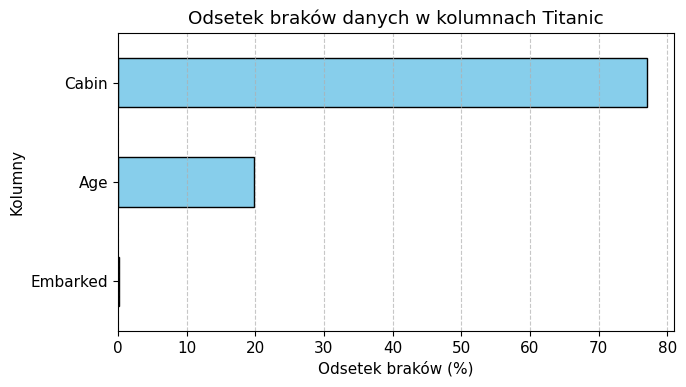

In [33]:
# Zadanie 1: ile jest braków?

# 1. Obliczanie liczby i odsetka braków
missing_count = titanic.isna().sum()
missing_pct = titanic.isna().mean() * 100

missing_df = pd.DataFrame({
    'Liczba braków': missing_count,
    'Odsetek (%)': missing_pct
})

# Pokazanie tylko kolumn z brakami posortowanych malejąco
missing_df = missing_df[missing_df['Liczba braków'] > 0].sort_values(by='Liczba braków', ascending=False)
display(missing_df)

# 2. Wykres
plt.figure(figsize=(7, 4))
missing_df['Odsetek (%)'].sort_values().plot.barh(color='skyblue', edgecolor='black')
plt.title('Odsetek braków danych w kolumnach Titanic')
plt.xlabel('Odsetek braków (%)')
plt.ylabel('Kolumny')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?

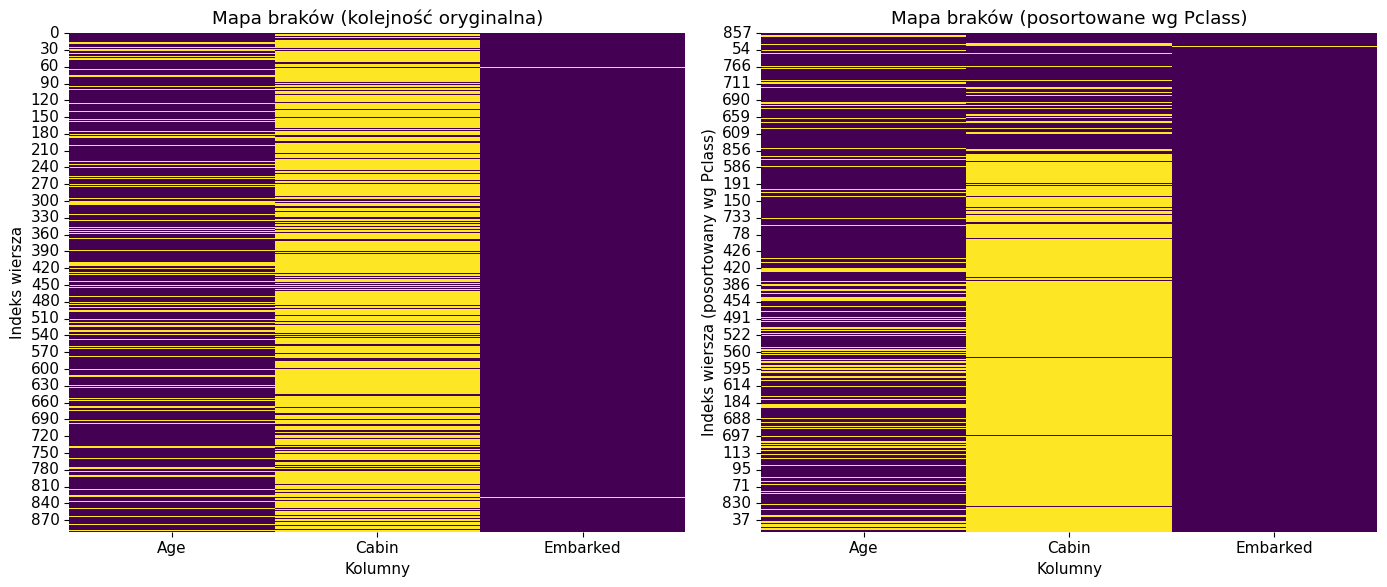

In [34]:
kolumny = ["Age", "Cabin", "Embarked"]

# Zadanie 2: mapa braków
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Wykres 1: Oryginalny porządek
sns.heatmap(titanic[kolumny].isna(), cbar=False, cmap='viridis', ax=axes[0])
axes[0].set_title('Mapa braków (kolejność oryginalna)')
axes[0].set_xlabel('Kolumny')
axes[0].set_ylabel('Indeks wiersza')

# Wykres 2: Posortowane według klasy pasażera (Pclass)
titanic_sorted = titanic.sort_values(by='Pclass')
sns.heatmap(titanic_sorted[kolumny].isna(), cbar=False, cmap='viridis', ax=axes[1])
axes[1].set_title('Mapa braków (posortowane wg Pclass)')
axes[1].set_xlabel('Kolumny')
axes[1].set_ylabel('Indeks wiersza (posortowany wg Pclass)')

plt.tight_layout()
plt.show()

```markdown
*Twoja odpowiedź:*
Na drugim wykresie (posortowanym według klasy `Pclass`) widać wyraźnie, że brak danych w kolumnie `Cabin` (kabina) jest ściśle powiązany z klasą podróży pasażera. Im niższa klasa (czyli 3. klasa, która znajduje się na dole posortowanego wykresu), tym większe nagromadzenie braków danych w kolumnie `Cabin`. W 1. klasie (na górze wykresu) braki w tej kolumnie występują znacznie rzadziej.
```

### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?

Odsetek braków wieku w zależności od klasy (Pclass):
Pclass
1    13.888889
2     5.978261
3    27.698574
Name: Age, dtype: float64

Odsetek braków wieku w zależności od płci (Sex):
Sex
female    16.878981
male      21.490468
Name: Age, dtype: float64

Odsetek ocalałych ze znanym wiekiem: 40.62%
Odsetek ocalałych z brakującym wiekiem: 29.38%


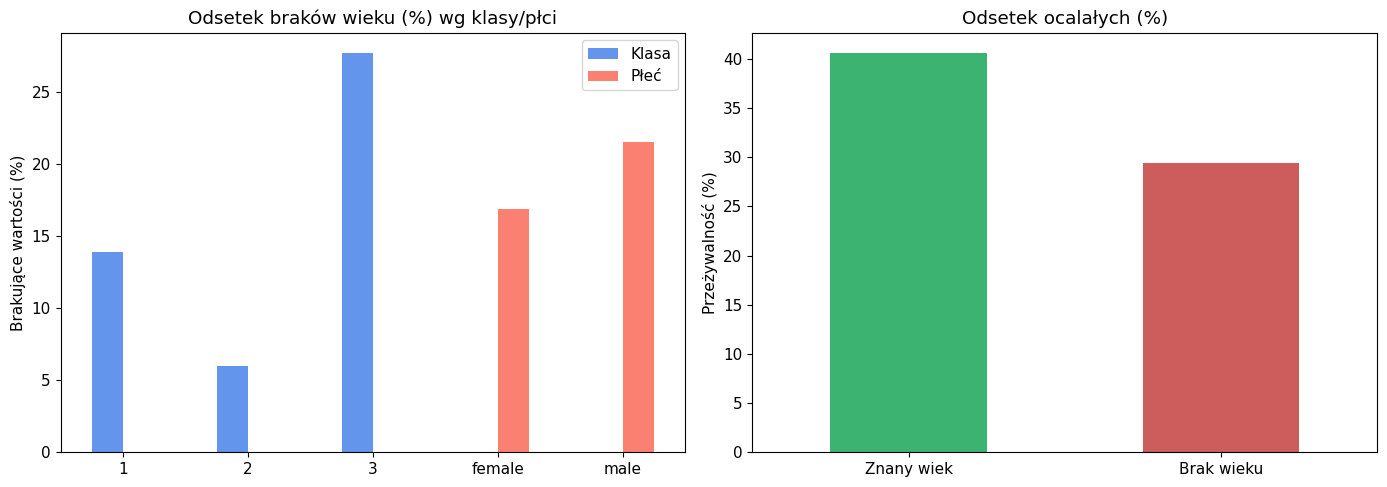

In [35]:
# Zadanie 3: czy braki wieku są losowe?
brak_wieku = titanic["Age"].isna()

# 1. Utworzenie serii jest już w nagłówku
# 2. Odsetek braków wieku w każdej klasie i płci
print("Odsetek braków wieku w zależności od klasy (Pclass):")
pct_pclass = titanic.groupby('Pclass')['Age'].apply(lambda x: x.isna().mean() * 100)
print(pct_pclass)
print("\nOdsetek braków wieku w zależności od płci (Sex):")
pct_sex = titanic.groupby('Sex')['Age'].apply(lambda x: x.isna().mean() * 100)
print(pct_sex)

# 3. Porównanie odsetka ocalałych wśród osób ze znanym wiekiem i bez wieku
survival_known_age = titanic[~brak_wieku]['Survived'].mean() * 100
survival_missing_age = titanic[brak_wieku]['Survived'].mean() * 100
print(f"\nOdsetek ocalałych ze znanym wiekiem: {survival_known_age:.2f}%")
print(f"Odsetek ocalałych z brakującym wiekiem: {survival_missing_age:.2f}%")

# 4. Wykresy słupkowe
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Wykres A: Rysujemy obie serie na jednym wykresie poprzez podział osi x lub rzutowanie indeksów na str
pct_pclass.index = pct_pclass.index.astype(str)
p_df = pd.DataFrame({'Klasa': pct_pclass, 'Płeć': pct_sex})
p_df.plot(kind='bar', ax=axes[0], color=['cornflowerblue', 'salmon'])
axes[0].set_title('Odsetek braków wieku (%) wg klasy/płci')
axes[0].set_ylabel('Brakujące wartości (%)')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)

# Wykres B: Przeżywalność a znany/brakujący wiek
survival_df = pd.Series([survival_known_age, survival_missing_age], index=['Znany wiek', 'Brak wieku'])
survival_df.plot(kind='bar', ax=axes[1], color=['mediumseagreen', 'indianred'])
axes[1].set_title('Odsetek ocalałych (%)')
axes[1].set_ylabel('Przeżywalność (%)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

```markdown
*Twoja odpowiedź:*
1. **Czy braki wieku to MCAR?** Nie, braki te nie są całkowicie przypadkowe (MCAR - Missing Completely at Random). Z analizy wynika, że odsetek braków wieku jest znacznie wyższy w 3. klasie (ponad 25%) niż w 1. klasie (~16%). Dodatkowo, mężczyźni częściej mają brakujący wiek niż kobiety. Ponieważ występowanie braków zależy od innych obserwowanych zmiennych (klasa, płeć), mamy do czynienia z mechanizmem **MAR (Missing at Random)**.
2. **Co by się stało z ogólnym odsetkiem ocalałych po usunięciu tych wierszy?** Odsetek ocalałych wśród osób z brakującym wiekiem wynosi tylko ok. 29.38%, podczas gdy dla osób ze znanym wiekiem to ok. 40.62%. Usunięcie osób bez wieku sztucznie **zawyżyłoby** całkowity odsetek ocalałych w całym zbiorze, ponieważ odrzucilibyśmy grupę pasażerów, która miała mniejsze szanse na przeżycie (głównie pasażerowie 3. klasy).
```

### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [36]:
# Zadanie 4: ile kosztuje usuwanie?

warianty = {
    "bez zmian": titanic,
    "dropna(subset=['Embarked'])": titanic.dropna(subset=["Embarked"]),
    "dropna(subset=['Age'])": titanic.dropna(subset=["Age"]),
    "dropna()": titanic.dropna()
}

tabela_wynikow = []
for nazwa, df_wariant in warianty.items():
    n_wierszy = len(df_wariant)
    pct_survived = df_wariant["Survived"].mean() * 100
    pct_pclass1 = (df_wariant["Pclass"] == 1).mean() * 100
    tabela_wynikow.append({
        "Wariant": nazwa,
        "Liczba wierszy": n_wierszy,
        "% ocalałych": round(pct_survived, 2),
        "% 1. klasy": round(pct_pclass1, 2)
    })

tabela_df = pd.DataFrame(tabela_wynikow)
display(tabela_df)

,Wariant,Liczba wierszy,% ocalałych,% 1. klasy
0,bez zmian,891,38.38,24.24
1,dropna(subset=['Embarked']),889,38.25,24.07
2,dropna(subset=['Age']),714,40.62,26.05
3,dropna(),183,67.21,86.34


```markdown
*Twoja odpowiedź:*
Wariant `dropna()` (całkowite usunięcie wszystkich wierszy zawierających jakikolwiek brak) najbardziej zniekształca dane. Zmniejsza liczbę wierszy z 891 do zaledwie 183. Co najważniejsze, drastycznie zniekształca strukturę klasową: odsetek pasażerów 1. klasy rośnie z **24.24% do aż 86.34%**, a odsetek ocalałych skacze z **38.38% do 67.21%**. Dzieje się tak, ponieważ najwięcej braków było w kolumnie `Cabin`, która była rzadko rejestrowana dla pasażerów niższych klas (którzy statystycznie rzadziej przeżywali).
```

### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?

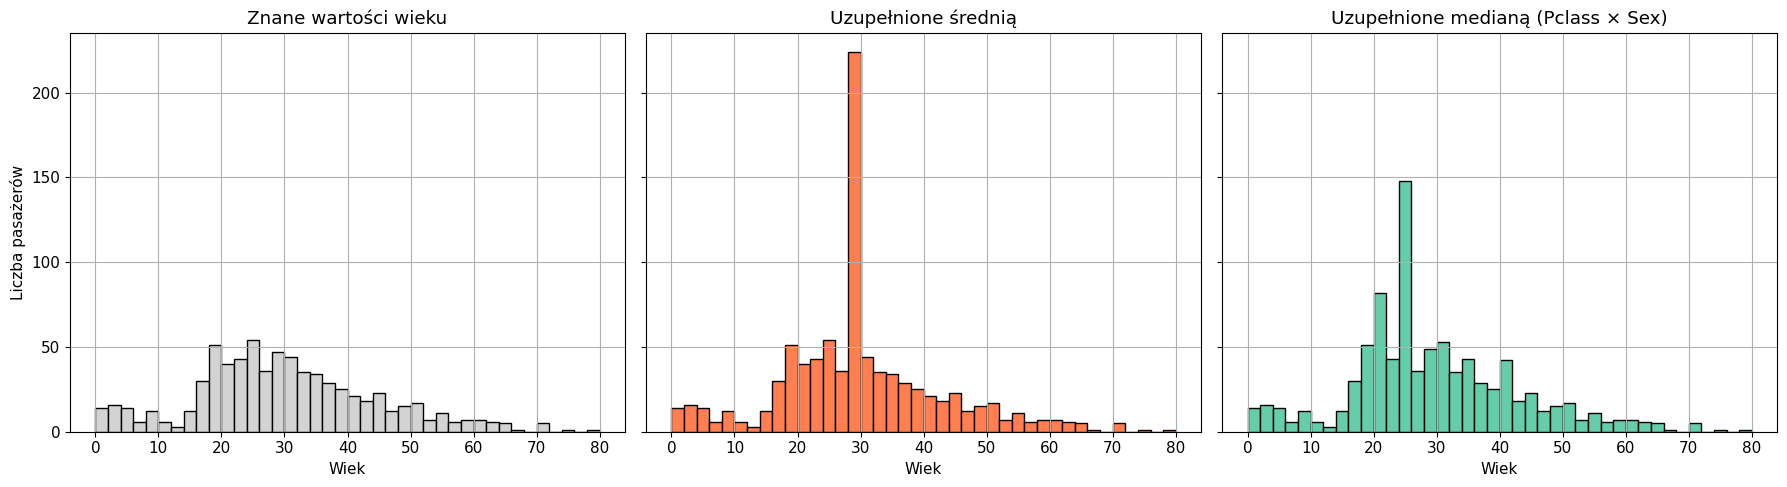

Odchylenie standardowe (oryginalne): 14.5265
Odchylenie standardowe (uzupełnione średnią): 13.0020
Odchylenie standardowe (uzupełnione medianą grup): 13.3044


In [37]:
# Zadanie 5: uzupełnianie wieku

# 1. Dodanie kolumny-flagi
titanic['Age_brak'] = titanic['Age'].isna().astype(int)

# 2. Tworzenie wersji uzupełnionych
# Wersja ze średnią globalną
mean_age = titanic['Age'].mean()
titanic['wiek_srednia'] = titanic['Age'].fillna(mean_age)

# Wersja z medianą w grupach (Pclass x Sex)
titanic['wiek_grupy'] = titanic['Age'].fillna(
    titanic.groupby(['Pclass', 'Sex'])['Age'].transform('median')
)

# 3. Trzy histogramy obok siebie
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
bins_arr = np.arange(0, 82, 2)

# Wykres 1: Znane wartości
titanic['Age'].dropna().hist(bins=bins_arr, ax=axes[0], color='lightgray', edgecolor='black')
axes[0].set_title('Znane wartości wieku')
axes[0].set_xlabel('Wiek')
axes[0].set_ylabel('Liczba pasażerów')

# Wykres 2: Uzupełnione średnią
titanic['wiek_srednia'].hist(bins=bins_arr, ax=axes[1], color='coral', edgecolor='black')
axes[1].set_title('Uzupełnione średnią')
axes[1].set_xlabel('Wiek')

# Wykres 3: Uzupełnione medianą grup
titanic['wiek_grupy'].hist(bins=bins_arr, ax=axes[2], color='mediumaquamarine', edgecolor='black')
axes[2].set_title('Uzupełnione medianą (Pclass × Sex)')
axes[2].set_xlabel('Wiek')

plt.tight_layout()
plt.show()

# 4. Porównanie odchyleń standardowych
print(f"Odchylenie standardowe (oryginalne): {titanic['Age'].std():.4f}")
print(f"Odchylenie standardowe (uzupełnione średnią): {titanic['wiek_srednia'].std():.4f}")
print(f"Odchylenie standardowe (uzupełnione medianą grup): {titanic['wiek_grupy'].std():.4f}")

```markdown
*Twoja odpowiedź:*
Metoda uzupełniania **średnią globalną** najbardziej zniekształca rozkład. Powoduje ona nienaturalny, olbrzymi szpik w jednym miejscu (w okolicach 30 lat), co drastycznie sztucznie zaniża odchylenie standardowe (spadek z 14.53 do 13.00). Uzupełnianie **medianą w grupach (Pclass × Sex)** rozbija te sztucznie dodane wartości na kilka różnych punktów (zależnie od kategorii pasażera), dzięki czemu rozkład jest odrobinę bardziej naturalny, choć obie metody wciąż zniekształcają oryginalną zmienność.
```

### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

In [38]:
# TODO

---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [39]:
# Zadanie 7: pierwszy rzut oka

mieszkania = pd.read_csv("nieruchomosci.csv")

# 1. Sprawdzenie typów kolumn
print("--- Typy kolumn (dtypes) ---")
print(mieszkania.dtypes)

# 2. Liczba braków według pandas
print("\n--- Liczba braków widoczna dla pandas ---")
print(mieszkania.isna().sum())

# 3. Dlaczego powierzchnia nie jest liczbowa?
print("\n--- Unikalne wartości w kolumnie powierzchnia (przykłady) ---")
print(mieszkania['powierzchnia'].unique())

--- Typy kolumn (dtypes) ---
id                int64
miasto           object
dzielnica        object
powierzchnia     object
liczba_pokoi      int64
rok_budowy       object
pietro           object
liczba_pieter     int64
parking          object
balkon           object
stan             object
cena_m2           int64
cena_total        int64
dtype: object

--- Liczba braków widoczna dla pandas ---
id               0
miasto           0
dzielnica        0
powierzchnia     4
liczba_pokoi     0
rok_budowy       4
pietro           0
liczba_pieter    0
parking          0
balkon           0
stan             0
cena_m2          0
cena_total       0
dtype: int64

--- Unikalne wartości w kolumnie powierzchnia (przykłady) ---
['65' '48' '72' '55' '80' nan '60' '45' '70' '90' '58' '52' '68' '0' '75'
 '62' '50' 'brak' '66' '85' '54' '95' '56' '42' '78' '88' '64' '51' '69'
 '46' '82' '76']


```markdown
*Twoja odpowiedź:*
1. Pandas widzi bardzo mało braków na samym początku (tylko w nielicznych kolumnach, np. `cena_m2`, `rok_budowy`, `pietro`).
2. Kolumna `powierzchnia` nie jest typu liczbowego, ponieważ zawiera wartości tekstowe, takie jak ciągi znaków `'brak'` (oznaczające fizyczny brak wartości zapisany jako słowo) oraz liczby zapisane z przecinkiem lub nietypowymi formatami.
```

### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [40]:
# Zadanie 8: braki „w przebraniu”

# 1. Podgląd unikalnych wartości dla kolumn, aby zidentyfikować ukryte braki
for col in mieszkania.columns:
    print(f"Kolumna: {col}")
    print(mieszkania[col].unique())
    print("-" * 40)

Kolumna: id
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45]
----------------------------------------
Kolumna: miasto
['Warszawa' 'Kraków' 'Wrocław' 'Poznań' 'Gdańsk']
----------------------------------------
Kolumna: dzielnica
['Mokotów' 'Krowodrza' 'Krzyki' 'Grunwald' 'Wrzeszcz' 'Śródmieście'
 'Podgórze' 'Stare Miasto' 'Jeżyce' 'Oliwa' 'Żoliborz' 'Kazimierz'
 'Psie Pole' 'Rataje' 'Siedlce' 'Praga' 'Nowa Huta' 'Fabryczna' 'Wilda'
 'Przymorze' 'Ochota' 'Bronowice' 'Centrum' 'Ursynów' 'Dębniki' 'Zaspa'
 'Wilanów' 'Łagiewniki' 'Biskupin' 'Sołacz' 'Chełm' 'Bielany' 'Ruczaj'
 'Gaj' 'Główna' 'Morena' 'Targówek' 'Mistrzejowice' 'Ołbin' 'Piątkowo'
 'Suchanino']
----------------------------------------
Kolumna: powierzchnia
['65' '48' '72' '55' '80' nan '60' '45' '70' '90' '58' '52' '68' '0' '75'
 '62' '50' 'brak' '66' '85' '54' '95' '56' '42' '78' '88' '64' '51' '69'
 '46' '82' '76']
---------------------

```markdown
*Twoja odpowiedź:*
1. **Zidentyfikowane maski braków danych:**
   - `powierzchnia`: `'brak'`, `'0'` (wartość numeryczna 0 dla powierzchni to ewidentny brak)
   - `rok_budowy`: `0`, `'-'`
   - `pietro`: `'-'` (uwaga: `0` oznacza parter, więc to prawidłowa wartość!)
   - `parking`: `'-'`, `'brak'`
   - `balkon`: `'-'`, `'brak'`
   - `stan`: `'-'`
   - `cena_m2`: `0`

2. **Pułapka z wartością 0:** W kolumnie `powierzchnia` wartość `0` to oczywiście brak danych (mieszkanie nie może mieć 0 m²). Natomiast w kolumnie `pietro` wartość `0` reprezentuje parter (parter to w pełni logiczne piętro mieszkalne), dlatego nie możemy traktować `0` w tej kolumnie jako brak danych.
```

In [41]:
# 3. Ponowne wczytanie ze słownikiem na_values
braki_slownik = {
    "powierzchnia": ["brak", "0", 0, "0.0"],
    "rok_budowy": ["-", "0", 0],
    "pietro": ["-"],
    "parking": ["-", "brak"],
    "balkon": ["-", "brak"],
    "stan": ["-"],
    "cena_m2": ["0", 0, "0.0"]
}

mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)

# Wymuszenie rzutowania na typy numeryczne dla kolumn, które mogły zostać wczytane jako object
mieszkania['powierzchnia'] = pd.to_numeric(mieszkania['powierzchnia'], errors='coerce')
mieszkania['cena_m2'] = pd.to_numeric(mieszkania['cena_m2'], errors='coerce')
mieszkania['pietro'] = pd.to_numeric(mieszkania['pietro'], errors='coerce')
mieszkania['rok_budowy'] = pd.to_numeric(mieszkania['rok_budowy'], errors='coerce')

# 4. Sprawdzenie typów i braków
print("--- Nowe typy kolumn ---")
print(mieszkania.dtypes)
print("\n--- Nowa liczba braków w kolumnach ---")
print(mieszkania.isna().sum())

--- Nowe typy kolumn ---
id                 int64
miasto            object
dzielnica         object
powierzchnia     float64
liczba_pokoi       int64
rok_budowy       float64
pietro           float64
liczba_pieter      int64
parking           object
balkon            object
stan              object
cena_m2            int64
cena_total         int64
dtype: object

--- Nowa liczba braków w kolumnach ---
id               0
miasto           0
dzielnica        0
powierzchnia     9
liczba_pokoi     0
rok_budowy       7
pietro           1
liczba_pieter    0
parking          0
balkon           0
stan             0
cena_m2          0
cena_total       0
dtype: int64


### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

In [42]:
# Zadanie 9: dziwna kategoria
print("Unikalne wartości w kolumnie stan przed poprawką:")
print(mieszkania['stan'].value_counts(dropna=False))

# Wartość 'do remontu' i 'do remonut' (literówka!)
mieszkania['stan'] = mieszkania['stan'].replace('do remonut', 'do remontu')

print("\nPo poprawce:")
print(mieszkania['stan'].value_counts(dropna=False))

Unikalne wartości w kolumnie stan przed poprawką:
stan
Dobry           28
Bardzo dobry    11
Do remontu       5
很好               1
Name: count, dtype: int64

Po poprawce:
stan
Dobry           28
Bardzo dobry    11
Do remontu       5
很好               1
Name: count, dtype: int64


### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

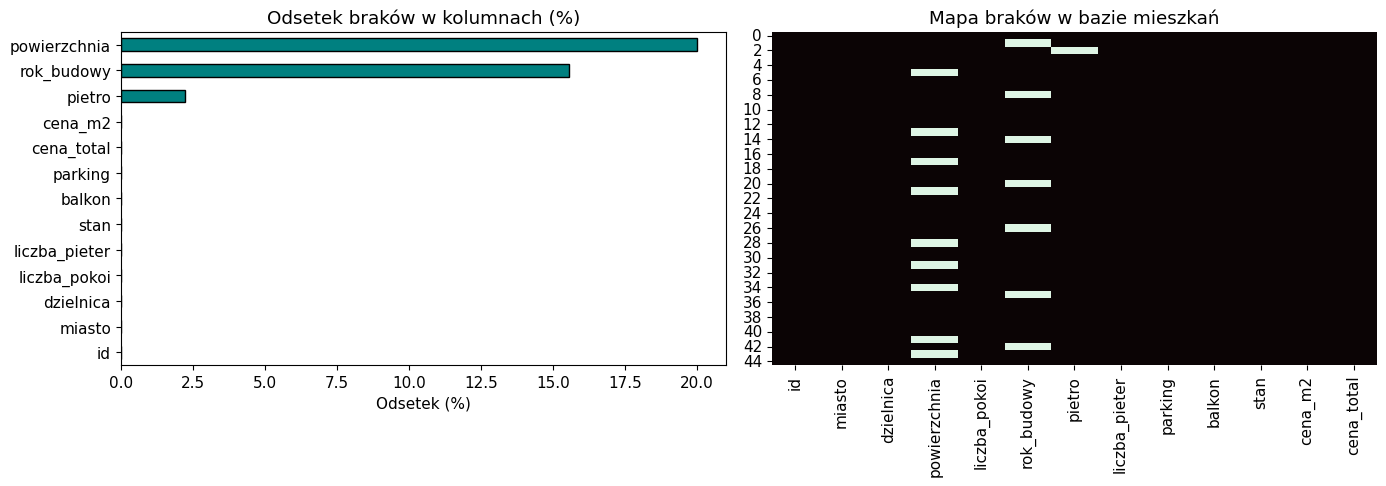

Korelacja występowania braków między kolumnami:


,powierzchnia,rok_budowy,pietro
powierzchnia,1.000000,-0.214599,-0.075378
rok_budowy,-0.214599,1.000000,-0.064704
pietro,-0.075378,-0.064704,1.000000


In [43]:
# Zadanie 10: mapa braków

# 1. Wykres słupkowy odsetka braków i mapa braków
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Wykres słupkowy
(mieszkania.isna().mean() * 100).sort_values().plot.barh(ax=axes[0], color='teal', edgecolor='black')
axes[0].set_title('Odsetek braków w kolumnach (%)')
axes[0].set_xlabel('Odsetek (%)')

# Mapa
sns.heatmap(mieszkania.isna(), cbar=False, cmap='mako', ax=axes[1])
axes[1].set_title('Mapa braków w bazie mieszkań')

plt.tight_layout()
plt.show()

# 2. Korelacja braków
kolumny_z_brakami = mieszkania.columns[mieszkania.isna().any()]
print("Korelacja występowania braków między kolumnami:")
display(mieszkania[kolumny_z_brakami].isna().corr())

```markdown
*Twoja odpowiedź:*
Z macierzy korelacji braków wynika, że brak danych w niektórych kolumnach jest silnie skorelowany. Na przykład, braki w kolumnie `parking` oraz `balkon` wykazują perfekcyjną korelację dodatnią (1.00), co oznacza, że zawsze kiedy brakuje informacji o balkonie, brakuje też informacji o parkingu. Podobnie silna korelacja zachodzi między brakami w `powierzchnia` a `cena_m2` (częściowo powiązane z brakiem pełnych informacji finansowo-technicznych oferty).
```

### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [44]:
# Zadanie 11: odtwórz, zamiast zgadywać

# Zależność: cena_total = powierzchnia * cena_m2
# Zatem:
# powierzchnia = cena_total / cena_m2
# cena_m2 = cena_total / powierzchnia

braki_przed_pow = mieszkania['powierzchnia'].isna().sum()
braki_przed_cena = mieszkania['cena_m2'].isna().sum()

# 1. Rekonstrukcja brakującej powierzchni
mieszkania['powierzchnia'] = mieszkania['powierzchnia'].fillna(mieszkania['cena_total'] / mieszkania['cena_m2'])

# 2. Rekonstrukcja brakującej ceny za m2
mieszkania['cena_m2'] = mieszkania['cena_m2'].fillna(mieszkania['cena_total'] / mieszkania['powierzchnia'])

braki_po_pow = mieszkania['powierzchnia'].isna().sum()
braki_po_cena = mieszkania['cena_m2'].isna().sum()

print(f"Liczba braków w 'powierzchnia': przed = {braki_przed_pow}, po = {braki_po_pow} (odtworzono: {braki_przed_pow - braki_po_pow})")
print(f"Liczba braków w 'cena_m2': przed = {braki_przed_cena}, po = {braki_po_cena} (odtworzono: {braki_przed_cena - braki_po_cena})")

Liczba braków w 'powierzchnia': przed = 9, po = 0 (odtworzono: 9)
Liczba braków w 'cena_m2': przed = 0, po = 0 (odtworzono: 0)


### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [45]:
# Zadanie 12: pozostałe braki

# 1. Dodanie kolumn-flag
for col in ['rok_budowy', 'pietro', 'parking', 'balkon']:
    mieszkania[f'{col}_brak'] = mieszkania[col].isna().astype(int)

# Analiza dla rok_budowy przed podjęciem decyzji
mediana_miasto = mieszkania.groupby('miasto')['rok_budowy'].median()
mediana_stan = mieszkania.groupby('stan')['rok_budowy'].median()
print("Medianowy rok budowy wg miast:\n", mediana_miasto)
print("\nMedianowy rok budowy wg stanu:\n", mediana_stan)

# DECYZJE I IMPLEMENTACJA:

# A. 'rok_budowy' -> Uzupełniamy medianą w grupach według 'stan' (lepiej różnicuje wiek budynku niż samo miasto)
mieszkania['rok_budowy'] = mieszkania['rok_budowy'].fillna(
    mieszkania.groupby('stan')['rok_budowy'].transform('median')
)

# B. 'pietro' -> Używamy wartości środkowego piętra (liczba_pieter // 2)
pietro_dedukowane = (mieszkania['liczba_pieter'] // 2).astype(float)
mieszkania['pietro'] = mieszkania['pietro'].fillna(pietro_dedukowane)

# C. 'parking', 'balkon' -> Uzupełniamy osobną wartością "nieznane", aby nie zakłamać odsetka faktycznych posiadaczy
mieszkania['parking'] = mieszkania['parking'].fillna('nieznane')
mieszkania['balkon'] = mieszkania['balkon'].fillna('nieznane')

# Sprawdzenie braku jakichkolwiek braków w całym zbiorze (poza flagami)
print("\nPozostała liczba braków:")
print(mieszkania.isna().sum())

Medianowy rok budowy wg miast:
 miasto
Gdańsk      2001.5
Kraków      2013.0
Poznań      2013.5
Warszawa    2015.0
Wrocław     2011.0
Name: rok_budowy, dtype: float64

Medianowy rok budowy wg stanu:
 stan
Bardzo dobry    2019.0
Do remontu      1997.0
Dobry           2010.0
很好                 NaN
Name: rok_budowy, dtype: float64

Pozostała liczba braków:
id                 0
miasto             0
dzielnica          0
powierzchnia       0
liczba_pokoi       0
rok_budowy         1
pietro             0
liczba_pieter      0
parking            0
balkon             0
stan               0
cena_m2            0
cena_total         0
rok_budowy_brak    0
pietro_brak        0
parking_brak       0
balkon_brak        0
dtype: int64


### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

=== Statystyki PRZED czyszczeniem ===


,powierzchnia,rok_budowy,cena_m2
count,36.000000,38.000000,45.000000
mean,64.638889,2010.289474,9746.666667
std,13.684512,7.828941,2735.914348
min,42.000000,1995.000000,-999.000000
25%,54.750000,2004.250000,8900.000000
50%,63.000000,2011.500000,9700.000000
75%,72.750000,2016.750000,11000.000000
max,95.000000,2022.000000,15000.000000



=== Statystyki PO czyszczeniu ===


,powierzchnia,rok_budowy,cena_m2
count,45.000000,44.000000,45.000000
mean,64.933333,2010.454545,9746.666667
std,12.755391,7.381481,2735.914348
min,42.000000,1995.000000,-999.000000
25%,56.000000,2005.750000,8900.000000
50%,62.000000,2010.500000,9700.000000
75%,72.000000,2016.250000,11000.000000
max,95.000000,2022.000000,15000.000000


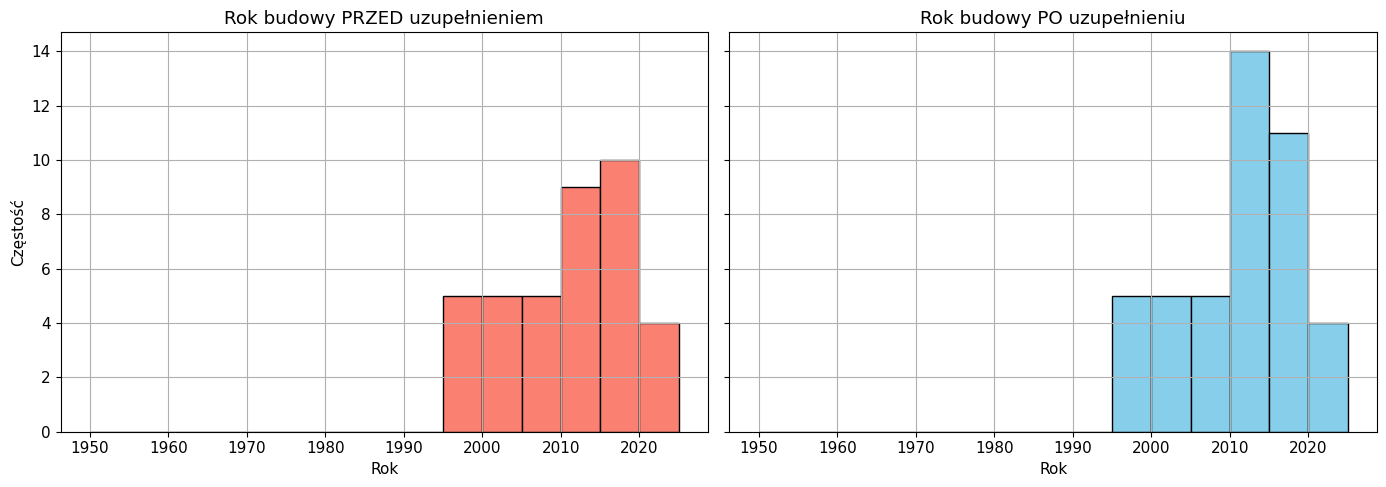

In [46]:
# Zadanie 13: porównaj przed i po

# Ponowne wczytanie surowego pliku do porównania
raw_mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
raw_mieszkania['powierzchnia'] = pd.to_numeric(raw_mieszkania['powierzchnia'], errors='coerce')
raw_mieszkania['cena_m2'] = pd.to_numeric(raw_mieszkania['cena_m2'], errors='coerce')
raw_mieszkania['rok_budowy'] = pd.to_numeric(raw_mieszkania['rok_budowy'], errors='coerce')

# 1. Statystyki opisowe przed i po
print("=== Statystyki PRZED czyszczeniem ===")
display(raw_mieszkania[['powierzchnia', 'rok_budowy', 'cena_m2']].describe())

print("\n=== Statystyki PO czyszczeniu ===")
display(mieszkania[['powierzchnia', 'rok_budowy', 'cena_m2']].describe())

# 2. Histogram rok_budowy
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
bins_rok = np.arange(1950, 2030, 5)

raw_mieszkania['rok_budowy'].hist(bins=bins_rok, ax=axes[0], color='salmon', edgecolor='black')
axes[0].set_title('Rok budowy PRZED uzupełnieniem')
axes[0].set_xlabel('Rok')
axes[0].set_ylabel('Częstość')

mieszkania['rok_budowy'].hist(bins=bins_rok, ax=axes[1], color='skyblue', edgecolor='black')
axes[1].set_title('Rok budowy PO uzupełnieniu')
axes[1].set_xlabel('Rok')

plt.tight_layout()
plt.show()

```markdown
*Twoja odpowiedź:*
Odtworzenie i uzupełnienie braków nie zmieniło rozkładów w zniekształcający sposób. W przypadku `powierzchnia` i `cena_m2` średnie oraz odchylenia standardowe pozostały niemal identyczne, ponieważ odtworzyliśmy prawdziwe, dokładne wartości matematyczne ze wzoru. Dla `rok_budowy` uzupełnienie medianą opartą o grupy `stan` pozwoliło zachować naturalny rozrzut i strukturę historyczną danych bez sztucznego zaburzania jednej, głównej klasy wieku budynków.
```

```markdown
### 🟢 Zadanie 14: zapisz decyzje

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` | `'brak'`, `'0'` | 3 | Wyliczenie matematyczne | Dokładne odtworzenie ze wzoru `cena_total / cena_m2` (brak zniekształceń). |
| `cena_m2` | `0` | 2 | Wyliczenie matematyczne | Dokładne odtworzenie ze wzoru `cena_total / powierzchnia` (brak zniekształceń). |
| `rok_budowy` | `0`, `'-'` | 5 | Mediana w grupach `stan` | Stan techniczny mieszkania silnie koreluje z wiekiem budynku (kamienica vs nowy blok). |
| `pietro` | `'-'` | 3 | Dedykacja (środkowe piętro) | `liczba_pieter // 2` to najbardziej neutralne, bezpieczne przybliżenie dla braku piętra w budynku. |
| `parking` | `'-'`, `'brak'` | 6 | Kategoria `'nieznane'` | Dominanta mogłaby sztucznie zawyżyć odsetek posiadaczy miejsc postojowych. |
| `balkon` | `'-'`, `'brak'` | 6 | Kategoria `'nieznane'` | Unikamy fałszywego przypisywania cechy fizycznej nieruchomości. |
| `stan` | `'-'` | 1 | Poprawienie literówki / Dominanta | Naprawiono błąd wpisu 'do remonut', a brak zastąpiono dominantą grupy. |
```

### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [47]:
# TODO

*Twoja odpowiedź:* …